- This is a multiclass classification problem. We have 10 classes (digits from 0 to 9) and we want to classify the input images into one of these classes.

In [1]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Flatten

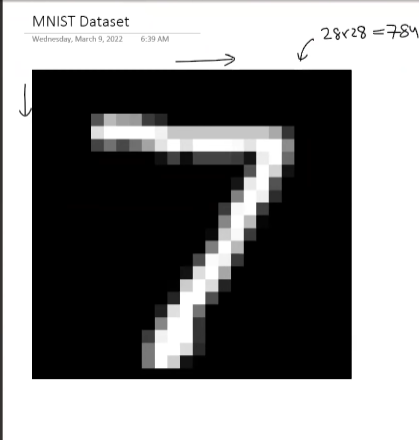

In [2]:
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
import numpy as np

In [9]:
arr = np.array([[1,2,3],[4,5,6]])
arr.shape,arr.ndim

((2, 3), 2)

In [10]:
arr1 = np.array([[[1,2,3],[4,5,6]],[[7,8,9],[10,11,12]],[[13,14,15],[16,17,18]],[[19,20,21],[22,23,24]]])
arr1.shape,arr1.ndim 

((4, 2, 3), 3)

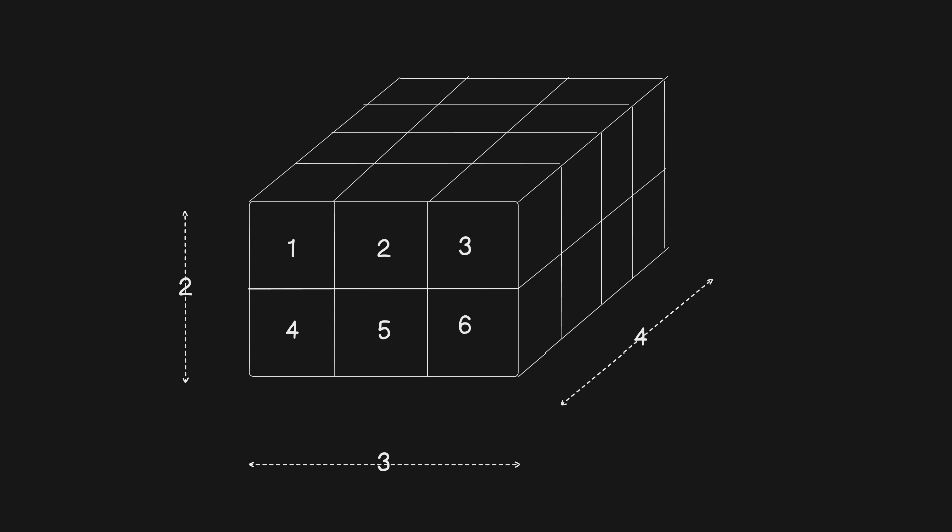

In [3]:
X_test.shape 

(10000, 28, 28)

- So, its like all the images are stacked on top of each other and we want to classify them into one of the 10 classes.

In [13]:
X_train[2].shape

(28, 28)

In [4]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

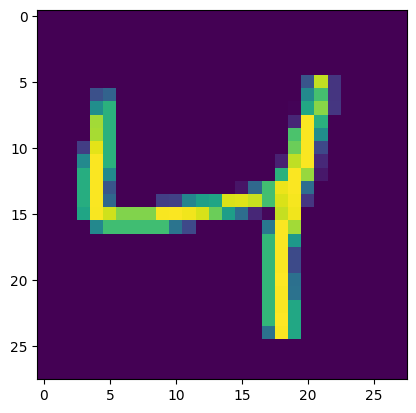

In [14]:
import matplotlib.pyplot as plt
plt.imshow(X_train[2])

In [16]:
print("X_train range:", X_train.min(), "to", X_train.max())
print("X_test range:", X_test.min(), "to", X_test.max())

X_train range: 0 to 255
X_test range: 0 to 255


- As you can see, the pixel values are between 0 and 255. We need to scale them to be between 0 and 1 before feeding them into the model. We can do this by dividing the pixel values by 255.

- When we train NN values jitne similar range mei hote hain, to weights utne sahi and jaldi converge karte hain. 

In [17]:
X_train = X_train/255
X_test = X_test/255

In [18]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [19]:
model = Sequential()

model.add(Flatten(input_shape=(28,28))) # Flatten 28*28 = 784
# In the below layer we no need to specify the input shape because it will automatically take the output shape of the previous layer as its input shape.
model.add(Dense(128,activation='relu')) # 1st hidden layer
model.add(Dense(10,activation='softmax')) # Output layer

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


- On flattening this happens:

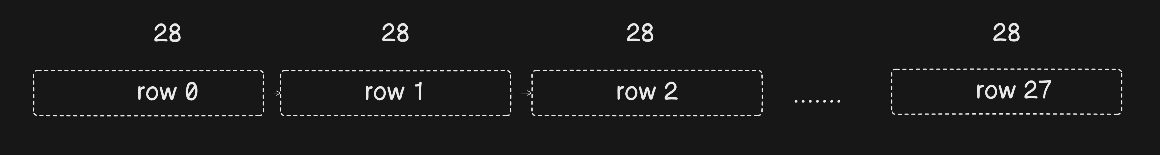

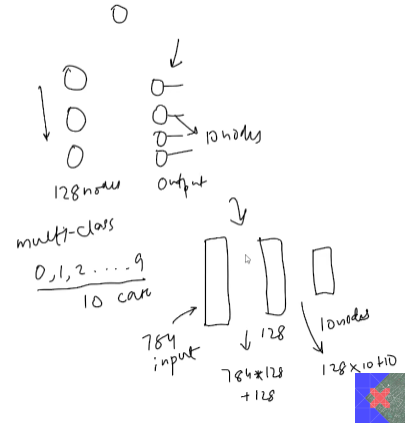

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

- The difference between 'sparse_categorical_crossentropy' and 'categorical_crossentropy' is that in 'sparse_categorical_crossentropy' we no need to one-hot encode the labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], whereas in 'categorical_crossentropy' we need to one-hot encode the labels. Since our labels are already in integer form (0-9), we can use 'sparse_categorical_crossentropy' without one-hot encoding them.

In [21]:
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [22]:
history = model.fit(X_train,y_train,epochs=25,validation_split=0.2)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9180 - loss: 0.2866 - val_accuracy: 0.9555 - val_loss: 0.1561
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9632 - loss: 0.1273 - val_accuracy: 0.9638 - val_loss: 0.1238
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9738 - loss: 0.0895 - val_accuracy: 0.9702 - val_loss: 0.0996
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9806 - loss: 0.0652 - val_accuracy: 0.9704 - val_loss: 0.0981
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9847 - loss: 0.0508 - val_accuracy: 0.9750 - val_loss: 0.0853
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9880 - loss: 0.0391 - val_accuracy: 0.9727 - val_loss: 0.0942
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9897 - loss: 0.0324 - val_accuracy: 0.9736 - val_loss: 0.0899
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9922 - loss: 0.0250 - 

In [23]:
y_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [24]:
y_pred = y_prob.argmax(axis=1)

In [25]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9747

- The accuracy can be more increased by changing the architecture of the model, adding more layers, changing the number of neurons in each layer, changing the activation function, changing the optimizer, changing the learning rate, etc.

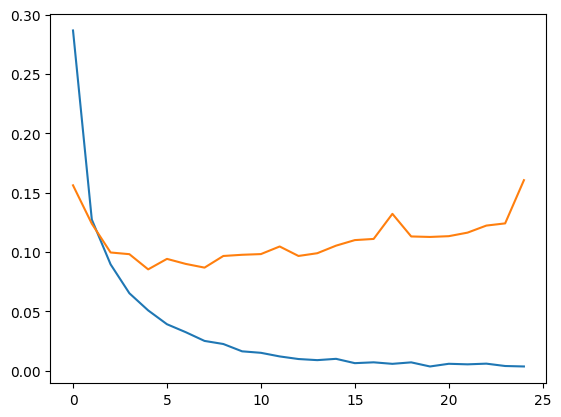

In [30]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

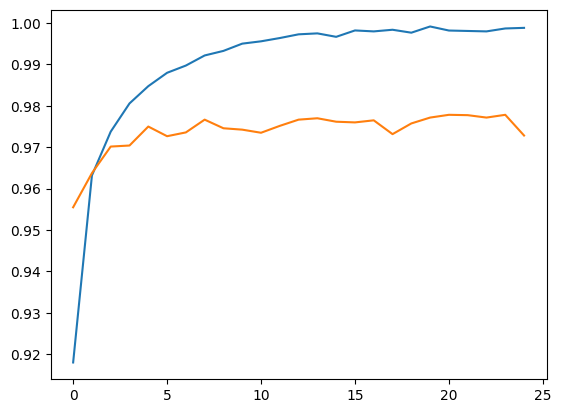

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

- So you can see there is slight overfitting in the model because the training accuracy is higher than the validation accuracy and also the training loss is lower than the validation loss. We can try to reduce this overfitting by adding dropout layers, adding regularization, etc. which we will study later

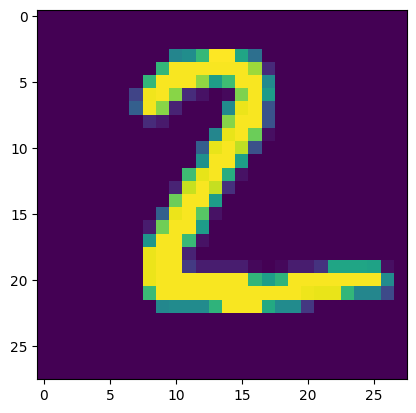

In [28]:
plt.imshow(X_test[1])

In [29]:
model.predict(X_test[1].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


array([2])